# CIE 2 – Activity 2: Binary Classification with Logistic Regression
**Course:** Regression and Classification Algorithms | **Class:** T.Y. B.Tech AI & DS, Div C, Sem V, 2026–27
**Name:** Ayush Rajgure | **Roll No.:** AD3304

> Role: data scientist in a hospital's breast-screening support team. A radiologist will look at the model's yes/no flag on a tumour sample, so my job is to show **how reliable the flag is and what it costs when it is wrong**.

## 1. Problem framing (stage 1)
- **Task:** predict whether a breast-mass sample is **malignant** (positive class, `1`) or **benign** (negative class, `0`) from measurements of cell nuclei in a digitised image.
- **Who acts on it / which decision:** a clinician decides whether a sample needs urgent follow-up. The model is a *decision aid*, not a diagnosis.
- **Cost of errors:** a **false negative** (malignant predicted benign) can delay cancer treatment, which is the worst outcome. A **false positive** (benign flagged as malignant) causes anxiety and extra tests, which is bad but recoverable. So **recall on the malignant class matters most**, while precision still matters to avoid flooding clinicians with false alarms.
- **Success metrics:** recall, precision, F1 and ROC-AUC (accuracy alone is not enough because classes are imbalanced), and a justified threshold.

## 2. Dataset (Step 1–2)

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, sklearn
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, roc_curve, roc_auc_score, precision_recall_curve,
                             average_precision_score)

SEED = 42
np.random.seed(SEED)
pd.set_option("display.precision", 4)
print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1


In [2]:
bc = load_breast_cancer(as_frame=True)
df = bc.frame.copy()
# scikit-learn codes 0 = malignant, 1 = benign. For screening I want the POSITIVE class to be the thing I must
# not miss (malignant), so I flip the coding: malignant = 1, benign = 0.
df["malignant"] = 1 - df["target"]
df = df.drop(columns="target")
print("Rows, columns:", df.shape)
df.iloc[:5, [0, 1, 2, 3, -1]]

Rows, columns: (569, 31)


,mean radius,mean texture,mean perimeter,mean area,malignant
0,17.99,10.38,122.80,1001.0,1
1,20.57,17.77,132.90,1326.0,1
2,19.69,21.25,130.00,1203.0,1
3,11.42,20.38,77.58,386.1,1
4,20.29,14.34,135.10,1297.0,1


**Source:** Wisconsin Diagnostic Breast Cancer (WDBC) dataset, Wolberg, Street & Mangasarian (1995), UCI Machine Learning Repository (https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic). Loaded via `sklearn.datasets.load_breast_cancer`. **Open data, de-identified:** the original patient ID column is not included, and I would not use it as a feature anyway. File type: in-memory DataFrame. 569 rows × 31 columns (30 features + target); I use **10** features (the "mean" measurements) to keep the model readable.

**One row** = one fine-needle-aspirate image of a breast mass, summarised by measurements of the cell nuclei.

**Classes:** `1` = **malignant** (cancerous, positive class), `0` = **benign** (non-cancerous, negative class).

In [3]:
FEATURES = [c for c in df.columns if c.startswith("mean ")]
TARGET = "malignant"
print(len(FEATURES), "features:", FEATURES)
print("\nMissing values:", int(df[FEATURES + [TARGET]].isna().sum().sum()), "| Duplicate rows:", int(df.duplicated().sum()))
print("Labels present in target:", sorted(int(v) for v in df[TARGET].unique()))
df[FEATURES].describe().T[["min", "mean", "max", "std"]]

10 features: ['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension']

Missing values: 0 | Duplicate rows: 0
Labels present in target: [0, 1]


,min,mean,max,std
mean radius,6.9810,14.1273,28.1100,3.5240
mean texture,9.7100,19.2896,39.2800,4.3010
mean perimeter,43.7900,91.9690,188.5000,24.2990
mean area,143.5000,654.8891,2501.0000,351.9141
mean smoothness,0.0526,0.0964,0.1634,0.0141
mean compactness,0.0194,0.1043,0.3454,0.0528
mean concavity,0.0000,0.0888,0.4268,0.0797
mean concave points,0.0000,0.0489,0.2012,0.0388
mean symmetry,0.1060,0.1812,0.3040,0.0274
mean fractal dimension,0.0500,0.0628,0.0974,0.0071


malignant
benign (0)       357
malignant (1)    212

Share malignant: 0.373


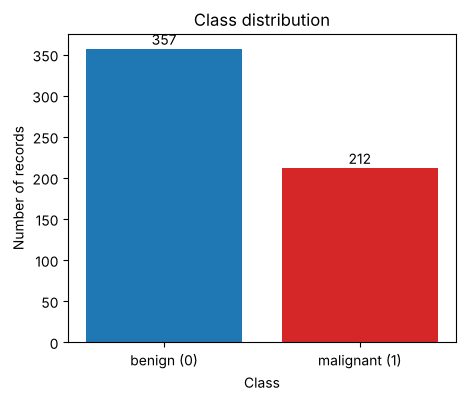

In [4]:
counts = df[TARGET].value_counts().sort_index()
print(counts.rename({0: "benign (0)", 1: "malignant (1)"}).to_string())
print("\nShare malignant:", round(counts[1] / len(df), 3))
plt.figure(figsize=(5, 4))
plt.bar(["benign (0)", "malignant (1)"], counts.values, color=["tab:blue", "tab:red"])
for i, v in enumerate(counts.values): plt.text(i, v + 5, str(v), ha="center")
plt.title("Class distribution"); plt.xlabel("Class"); plt.ylabel("Number of records")
plt.show()

**Observation:** no missing values, no duplicates and labels are consistent (only 0 and 1). The classes are **moderately imbalanced** (about 37 % malignant, 63 % benign), so a lazy model that always says "benign" would already reach ≈ 63 % accuracy. Accuracy alone will therefore be a weak yardstick.

**Possible issues to remember:** `radius`, `perimeter` and `area` measure almost the same thing (strongly correlated), and the data come from one study/hospital, so results may not transfer elsewhere.

## 3. Prepare features and split (Steps 3–4)

- **Missing values:** none, so no imputation. **Categorical features:** none, so no encoding needed. **Identifier columns:** none used.
- **Scaling:** features have very different ranges (area ≈ 100–2500, smoothness ≈ 0.05–0.16). Logistic regression is fit by gradient-based optimisation, and unscaled features of very different size make the optimiser slow or unstable and make the (regularised) coefficients unfair to compare. I use `StandardScaler`, **fitted on the training set only** and then applied to the test set.

In [5]:
X, y = df[FEATURES], df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print("Train size:", len(X_train), "| Test size:", len(X_test))
print("Train class counts:", y_train.value_counts().sort_index().to_dict(), "| share malignant:", round(y_train.mean(), 3))
print("Test  class counts:", y_test.value_counts().sort_index().to_dict(), "| share malignant:", round(y_test.mean(), 3))

scaler = StandardScaler().fit(X_train)          # fitted on TRAIN only: no test information leaks in
Xtr, Xte = scaler.transform(X_train), scaler.transform(X_test)

Train size: 455 | Test size: 114
Train class counts: {0: 285, 1: 170} | share malignant: 0.374
Test  class counts: {0: 72, 1: 42} | share malignant: 0.368


## 4. Why logistic regression? The sigmoid (Step 5)

**Why not linear regression for a class label?** Linear regression outputs any real number (−∞ to +∞), so it can predict "−0.4" or "1.7", which are not valid probabilities. Its straight line is also dragged around by extreme points, and its squared-error fit is not designed for yes/no targets. Logistic regression instead models the **probability** of the positive class.

**Sigmoid:** σ(z) = 1 / (1 + e^(−z)) squashes the linear score z = b0 + b1·x1 + … into a value between 0 and 1, which we read as P(malignant). A **decision threshold** (0.5 by default) then turns the probability into a label: predict malignant if P ≥ threshold.

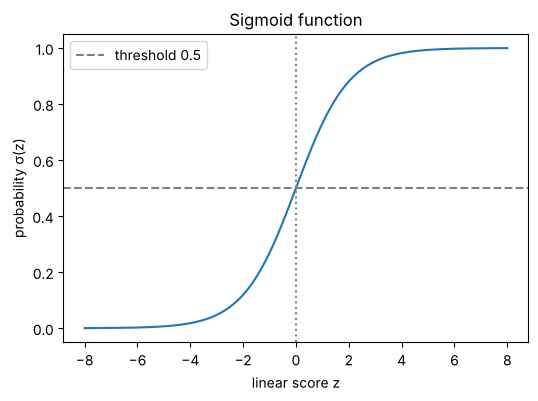

In [6]:
z = np.linspace(-8, 8, 200)
plt.figure(figsize=(6, 4))
plt.plot(z, 1 / (1 + np.exp(-z)))
plt.axhline(0.5, color="gray", ls="--", label="threshold 0.5"); plt.axvline(0, color="gray", ls=":")
plt.title("Sigmoid function"); plt.xlabel("linear score z"); plt.ylabel("probability σ(z)"); plt.legend()
plt.show()

## 5. Train the model (Step 6)

In [7]:
clf = LogisticRegression(max_iter=1000, random_state=SEED)   # default: L2 regularisation, C=1.0, lbfgs solver
clf.fit(Xtr, y_train)
print("Settings:", {k: v for k, v in clf.get_params().items() if k in ("C", "solver", "max_iter", "random_state")}, "(L2 penalty is the default)")
print("Intercept:", round(clf.intercept_[0], 4))
coefs = pd.DataFrame({"coefficient (per +1 std)": clf.coef_[0], "odds ratio": np.exp(clf.coef_[0])}, index=FEATURES)
coefs.sort_values("coefficient (per +1 std)", ascending=False)

Settings: {'C': 1.0, 'max_iter': 1000, 'random_state': 42, 'solver': 'lbfgs'} (L2 penalty is the default)
Intercept: -0.5257


,coefficient (per +1 std),odds ratio
mean concave points,1.6625,5.2724
mean texture,1.4899,4.4365
mean area,1.2207,3.3894
mean smoothness,1.1441,3.1397
mean radius,1.0518,2.8628
mean perimeter,0.9237,2.5185
mean concavity,0.8805,2.4121
mean symmetry,0.4313,1.5393
mean compactness,-0.2804,0.7555
mean fractal dimension,-0.4120,0.6623


**Reading the coefficients.** Features were standardised, so each coefficient is the change in the **log-odds of malignant** for a +1 standard-deviation increase in that feature, holding the others fixed; `odds ratio = e^coef` is the multiplicative change in the odds.
- **Positive coefficient → raises the probability of malignant.** The largest are `mean concave points` (odds ×5.3 per +1 SD), `mean texture` (×4.4), `mean area` (×3.4), `mean smoothness` (×3.1) and `mean radius` (×2.9).
- **Negative coefficient → lowers it:** `mean fractal dimension` (×0.66) and `mean compactness` (×0.76), both small.
- **Caution:** `radius`, `perimeter` and `area` are almost the same measurement, so the model splits their effect among them; read them together ("bigger nuclei → more likely malignant") rather than one by one. Coefficients show association, not cause, and L2 regularisation shrinks them slightly.

## 6. Probabilities, labels and thresholds (Step 7)

In [8]:
proba = clf.predict_proba(Xte)[:, 1]          # P(malignant)
pred05 = (proba >= 0.5).astype(int)
sample = pd.DataFrame({"actual": y_test.values, "P(malignant)": proba.round(3), "predicted @0.5": pred05}, index=y_test.index)
sample.head(10)

,actual,P(malignant),predicted @0.5
120,0,0.001,0
250,1,1.000,1
375,0,0.485,0
99,1,0.560,1
455,0,0.644,1
318,0,0.011,0
39,1,0.447,0
371,0,0.012,0
98,0,0.001,0
502,0,0.072,0


In [9]:
rows = []
for t in (0.3, 0.5, 0.7):
    rows.append({"threshold": t, "records predicted malignant": int((proba >= t).sum()), "out of": len(proba)})
pd.DataFrame(rows).set_index("threshold")

,records predicted malignant,out of
threshold,,
0.3,49,114
0.5,44,114
0.7,37,114


Lowering the threshold flags **more** records as malignant (more sensitive, more false alarms); raising it flags fewer (fewer false alarms, more misses).

## 7. Evaluation (Step 8)

TN = 67 | FP = 5 | FN = 3 | TP = 39


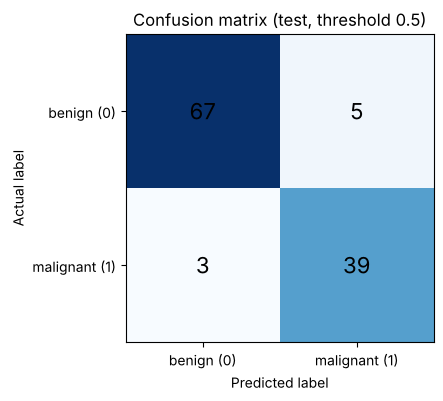

In [10]:
cm = confusion_matrix(y_test, pred05, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()
fig, ax = plt.subplots(figsize=(4.8, 4))
ax.imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm): ax.text(j, i, v, ha="center", va="center", fontsize=16, color="black")
ax.set_xticks([0, 1], ["benign (0)", "malignant (1)"]); ax.set_yticks([0, 1], ["benign (0)", "malignant (1)"])
ax.set_xlabel("Predicted label"); ax.set_ylabel("Actual label"); ax.set_title("Confusion matrix (test, threshold 0.5)")
plt.show()
print(f"TN = {tn} | FP = {fp} | FN = {fn} | TP = {tp}")

**What each cell means here (test set, 114 records):**
- **TN = 67:** benign samples correctly cleared (no unnecessary follow-up).
- **FP = 5:** benign samples wrongly flagged as malignant, leading to extra tests and worry.
- **FN = 3:** malignant samples the model **missed** (called benign). This is the most serious error because it can delay treatment.
- **TP = 39:** malignant samples correctly caught.

In [11]:
def metrics_at(y_true, p, t):
    yh = (p >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, yh, labels=[0, 1]).ravel()
    return {"Accuracy": (tp + tn) / (tp + tn + fp + fn),
            "Precision": tp / (tp + fp) if (tp + fp) else float("nan"),
            "Recall (sensitivity)": tp / (tp + fn),
            "Specificity": tn / (tn + fp),
            "F1-score": 2 * tp / (2 * tp + fp + fn),      # = 2PR/(P+R)
            "TP": tp, "FP": fp, "FN": fn, "TN": tn}

m = metrics_at(y_test, proba, 0.5)
auc = roc_auc_score(y_test, proba)
# cross-check my manual formulas against scikit-learn
assert np.isclose(m["Accuracy"], accuracy_score(y_test, pred05)) and np.isclose(m["Precision"], precision_score(y_test, pred05))
assert np.isclose(m["Recall (sensitivity)"], recall_score(y_test, pred05)) and np.isclose(m["F1-score"], f1_score(y_test, pred05))

summary = pd.DataFrame({
    "Formula": ["(TP+TN)/(TP+TN+FP+FN)", "TP/(TP+FP)", "TP/(TP+FN)", "TN/(TN+FP)", "2*P*R/(P+R)", "area under ROC curve"],
    "Test-set result": [m["Accuracy"], m["Precision"], m["Recall (sensitivity)"], m["Specificity"], m["F1-score"], auc]},
    index=["Accuracy", "Precision", "Recall (sensitivity)", "Specificity", "F1-score", "ROC-AUC"])
summary

,Formula,Test-set result
Accuracy,(TP+TN)/(TP+TN+FP+FN),0.9298
Precision,TP/(TP+FP),0.8864
Recall (sensitivity),TP/(TP+FN),0.9286
Specificity,TN/(TN+FP),0.9306
F1-score,2*P*R/(P+R),0.9070
ROC-AUC,area under ROC curve,0.9841


In [12]:
print(classification_report(y_test, pred05, target_names=["benign (0)", "malignant (1)"], digits=3))

               precision    recall  f1-score   support

   benign (0)      0.957     0.931     0.944        72
malignant (1)      0.886     0.929     0.907        42

     accuracy                          0.930       114
    macro avg      0.922     0.930     0.925       114
 weighted avg      0.931     0.930     0.930       114



In [13]:
# Baseline: always predict the majority class (benign)
dummy = DummyClassifier(strategy="most_frequent").fit(Xtr, y_train)
pd_ = dummy.predict(Xte)
base = pd.DataFrame({
    "Majority-class baseline": [accuracy_score(y_test, pd_), precision_score(y_test, pd_, zero_division=0), recall_score(y_test, pd_), f1_score(y_test, pd_)],
    "Logistic Regression": [m["Accuracy"], m["Precision"], m["Recall (sensitivity)"], m["F1-score"]]},
    index=["Accuracy", "Precision", "Recall", "F1-score"])
base

,Majority-class baseline,Logistic Regression
Accuracy,0.6316,0.9298
Precision,0.0000,0.8864
Recall,0.0000,0.9286
F1-score,0.0000,0.9070


**Interpretation (threshold 0.5):** accuracy ≈ 93.0 %. Precision ≈ 88.6 % means that of the 44 samples flagged malignant, about 89 % really were. Recall ≈ 92.9 % means the model found 39 of the 42 real malignant cases. Specificity ≈ 93.1 % means it correctly cleared 67 of 72 benign cases. F1 ≈ 0.907 balances precision and recall. ROC-AUC ≈ 0.984 means that if I pick one random malignant and one random benign sample, the model gives the malignant one the higher probability about 98 % of the time (0.5 would be chance).

**Baseline check:** the "always benign" baseline reaches ≈ 63 % accuracy **but finds zero cancers** (recall = 0). That is exactly why accuracy alone can mislead on imbalanced data. Logistic regression beats the baseline on every measure.

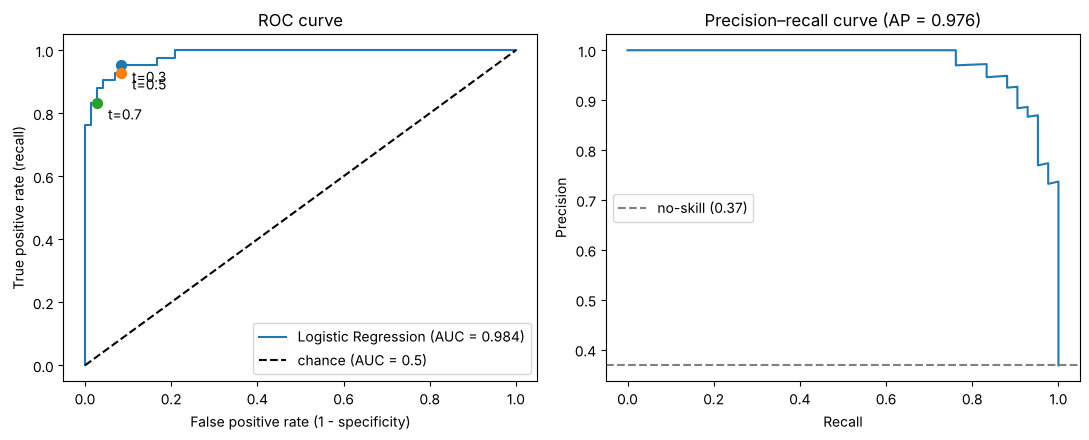

In [14]:
fpr, tpr, thr = roc_curve(y_test, proba)
prec, rec, _ = precision_recall_curve(y_test, proba)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
ax[0].plot(fpr, tpr, label=f"Logistic Regression (AUC = {auc:.3f})")
ax[0].plot([0, 1], [0, 1], "k--", label="chance (AUC = 0.5)")
for t in (0.3, 0.5, 0.7):
    i = np.argmin(np.abs(thr - t)); ax[0].scatter(fpr[i], tpr[i], s=50, zorder=5); ax[0].annotate(f"t={t}", (fpr[i], tpr[i]), textcoords="offset points", xytext=(8, -12))
ax[0].set_xlabel("False positive rate (1 - specificity)"); ax[0].set_ylabel("True positive rate (recall)"); ax[0].set_title("ROC curve"); ax[0].legend(loc="lower right")
ax[1].plot(rec, prec); ax[1].axhline(y_test.mean(), color="gray", ls="--", label=f"no-skill ({y_test.mean():.2f})")
ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision"); ax[1].set_title(f"Precision–recall curve (AP = {average_precision_score(y_test, proba):.3f})"); ax[1].legend()
plt.tight_layout(); plt.show()

The ROC curve hugs the top-left corner, which means high recall is achievable with a low false-positive rate. The dots mark thresholds 0.3, 0.5 and 0.7 on that curve: moving from 0.7 to 0.3 climbs the curve (more cancers found) while moving right (more false alarms). The precision–recall curve, which is more informative when classes are imbalanced, stays high until recall approaches 1, then precision falls as the model starts accepting more false alarms.

In [15]:
thr_table = pd.DataFrame({t: metrics_at(y_test, proba, t) for t in (0.3, 0.5, 0.7)}).T
thr_table.insert(0, "Predicted positive", [(proba >= t).sum() for t in (0.3, 0.5, 0.7)])
thr_table.index.name = "threshold"
thr_table[["Predicted positive", "Accuracy", "Precision", "Recall (sensitivity)", "F1-score", "FP", "FN"]]

,Predicted positive,Accuracy,Precision,Recall (sensitivity),F1-score,FP,FN
threshold,,,,,,,
0.3,49,0.9035,0.8163,0.9524,0.8791,9.0,2.0
0.5,44,0.9298,0.8864,0.9286,0.9070,5.0,3.0
0.7,37,0.9211,0.9459,0.8333,0.8861,2.0,7.0


**Trade-off:** lowering the threshold makes the model more eager to say "malignant".
- **0.3:** recall ≈ 95.2 % (only **2** cancers missed) but precision ≈ 81.6 % (**9** false alarms).
- **0.5:** recall ≈ 92.9 % (3 missed), precision ≈ 88.6 % (5 false alarms), the best F1 and accuracy.
- **0.7:** precision ≈ 94.6 % (only 2 false alarms) but recall drops to ≈ 83.3 % (**7** cancers missed).

**Which error costs more?** The **false negative**: a missed malignant tumour can delay treatment, while a false positive normally costs a confirmatory test.

**Recommendation:** use a **lower threshold of about 0.3** for the screening flag, accepting a few more false alarms (precision ≈ 82 %) in exchange for catching more cancers (recall ≈ 95 %). 0.7 is unacceptable as it misses 7 of 42 cancers. Caveat: the gap between 0.3 and 0.5 is only one patient on a 114-record test set, so before deployment I would pick the final threshold on a separate validation set (or with cross-validation) and consider going lower still.

In [16]:
# Train vs test (overfitting check) at threshold 0.5
ptr = clf.predict_proba(Xtr)[:, 1]
cmp = pd.DataFrame({"Train": metrics_at(y_train, ptr, 0.5), "Test": metrics_at(y_test, proba, 0.5)}).loc[["Accuracy", "Precision", "Recall (sensitivity)", "F1-score"]]
cmp.loc["ROC-AUC"] = [roc_auc_score(y_train, ptr), auc]
cmp

,Train,Test
Accuracy,0.9407,0.9298
Precision,0.9497,0.8864
Recall (sensitivity),0.8882,0.9286
F1-score,0.9179,0.9070
ROC-AUC,0.9877,0.9841


Train and test results are close (accuracy ≈ 94.1 % vs 93.0 %, ROC-AUC ≈ 0.988 vs 0.984), so there is **no sign of overfitting**. The train scores are not extremely high either, so a simple linear decision boundary may be slightly limiting (mild underfitting is possible). Test recall (92.9 %) being higher than train recall (88.8 %) is most likely noise from the small test set (only 42 malignant cases), not a real advantage.

## 8. Visualise the decision behaviour (Step 9)

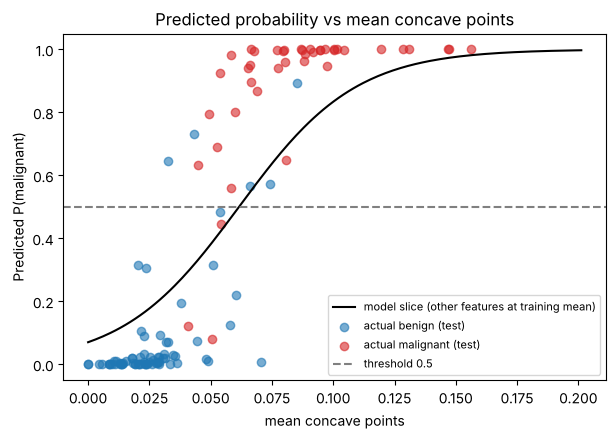

In [17]:
# Predicted probability vs ONE feature. Other features are held at their training mean (a one-feature "slice" of the model),
# and the actual test records are overlaid as points.
feat = "mean concave points"
fi = FEATURES.index(feat)
grid = np.linspace(X[feat].min(), X[feat].max(), 200)
base_row = X_train.mean().to_frame().T
sl = pd.concat([base_row] * len(grid), ignore_index=True); sl[feat] = grid
p_slice = clf.predict_proba(scaler.transform(sl))[:, 1]

plt.figure(figsize=(7, 4.5))
plt.plot(grid, p_slice, color="black", label="model slice (other features at training mean)")
plt.scatter(X_test[feat][y_test == 0], proba[(y_test == 0).values], c="tab:blue", alpha=0.6, label="actual benign (test)")
plt.scatter(X_test[feat][y_test == 1], proba[(y_test == 1).values], c="tab:red", alpha=0.6, label="actual malignant (test)")
plt.axhline(0.5, color="gray", ls="--", label="threshold 0.5")
plt.xlabel(feat); plt.ylabel("Predicted P(malignant)"); plt.title(f"Predicted probability vs {feat}"); plt.legend(fontsize=8)
plt.show()

The black curve shows how P(malignant) rises with `mean concave points` when the other features are held at their training mean. It crosses 0.5 at roughly 0.06, and the actual test records follow the same pattern: blue (benign) points sit at low values and low probability, red (malignant) at high values and high probability. The mixed region around 0.03–0.07 is where benign and malignant cases overlap and where the model makes its errors. Points do not lie exactly on the curve because real records also differ in the other nine features.

## 9. Classify a new example and conclude (Step 10)

In [18]:
new = pd.DataFrame([X_train.median()])      # start from a typical record...
new["mean radius"] = 17.0; new["mean perimeter"] = 112.0; new["mean area"] = 930.0
new["mean concavity"] = 0.12; new["mean concave points"] = 0.07   # ...and make it look more suspicious
inside = ((new.iloc[0] >= X.min()) & (new.iloc[0] <= X.max())).all()
print("All values inside the training range?", inside)
print(new.T.round(3).rename(columns={0: "new record"}).to_string())
p_new = clf.predict_proba(scaler.transform(new))[0, 1]    # same preprocessing (train-fitted scaler)
print(f"\nP(malignant) = {p_new:.3f}  ->  predicted class at 0.5: {'malignant' if p_new >= 0.5 else 'benign'}")

All values inside the training range? True
                        new record
mean radius                 17.000
mean texture                18.900
mean perimeter             112.000
mean area                  930.000
mean smoothness              0.095
mean compactness             0.092
mean concavity               0.120
mean concave points          0.070
mean symmetry                0.180
mean fractal dimension       0.061

P(malignant) = 0.955  ->  predicted class at 0.5: malignant


**New example:** a record with large, irregular nuclei (radius 17, area 930, concave points 0.07, all inside the training range) gets **P(malignant) ≈ 0.96**, so the model flags it as malignant at 0.5 and also at my recommended 0.3. The same preprocessing (train-fitted scaler) was applied.

**Conclusion.** A logistic regression trained on 455 samples with 10 nucleus measurements reaches ≈ 93 % accuracy, ≈ 93 % recall and ROC-AUC ≈ 0.98 on 114 unseen samples, far better than the majority-class baseline, which catches no cancers. Because a missed cancer is the costliest error, I recommend a lower threshold (≈ 0.3) that raises recall to ≈ 95 % at the price of more false alarms. Limits: a single dataset, a small test set, and a threshold that must be re-confirmed on validation data. The output is a probability-based estimate, **not a guaranteed outcome**, and must support, not replace, a clinician's judgement.

## Decision log
| # | Decision | Alternatives | Reason |
|---|---|---|---|
| 1 | Positive class = **malignant** | keep sklearn's coding (benign = 1) | the positive class should be the case we must not miss, so recall/precision refer to cancer detection |
| 2 | Used the 10 "mean" features only | all 30 features | simpler, easier to explain; the 20 "error/worst" columns are largely redundant |
| 3 | Stratified 80:20 split, `random_state=42` | random split, k-fold CV | keeps class ratio in both sets; CV would give a more stable estimate (next step) |
| 4 | `StandardScaler` fitted on train only | scale full data before splitting | prevents test information leaking into training |
| 5 | Default L2 logistic regression (C = 1) | tuning C, other models | baseline model first; tuning must use a validation set, not the test set |
| 6 | Main metric: **recall** (with precision/F1 and AUC) | accuracy | a missed cancer is the costliest error, and accuracy is inflated by the majority class |
| 7 | Threshold recommendation: see section 7, threshold table | default 0.5 | chosen from the cost of errors, not by habit |

## Limitations and ethics
- One dataset from one clinical setting (569 samples); test set has only 114 records, so each single error moves the percentages noticeably.
- The threshold was compared on the **test** set for this exercise; in real work I would choose it on a separate validation set or with cross-validation.
- A very high score here is partly because this is a well-studied, relatively "easy" dataset. I checked for leakage (no ID column, scaler fitted on train only, same preprocessing for test), but I would still validate on data from another hospital before any real use.
- **Should not be used to make a diagnosis on its own.** A positive or negative flag must be confirmed by clinicians and further tests. A false negative can delay treatment and a false positive can cause distress and unnecessary procedures. The output is a probability-based estimate, not a guaranteed outcome.